# Initial data exploration

Inspect the original UCI dataset before cleaning or modeling. This notebook records loading decisions and initial data quality checks.

## Imports and project paths

Load the shared dataset path from `code/paths.py`. The setup supports execution from the repository root or the `notebooks` directory. Check that the local XLS file exists before reading it.

In [1]:
import sys
from pathlib import Path

import pandas as pd

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent

sys.path.insert(0, str(root / "code"))

from paths import RAW_DATA_FILE

print(RAW_DATA_FILE)
print("Dataset exists:", RAW_DATA_FILE.is_file())

/workspaces/credit_defaulf_prediction/data/default_of_credit_card_clients.xls
Dataset exists: True


## Inspect the Excel layout

List the workbook sheets and preview the first rows with `header=None` so no row is interpreted as column names. This reveals the extra row of variable codes above the descriptive headers.

The current `xlrd` engine emits a deprecation warning in pandas. Reading succeeds; migrating to another supported engine remains a follow-up task.

In [2]:
excel = pd.ExcelFile(RAW_DATA_FILE, engine="xlrd")
print("Sheets:", excel.sheet_names)

preview = pd.read_excel(excel, sheet_name=0, header=None, nrows=8)
display(preview)

/tmp/ipykernel_56082/2254168469.py:1: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  excel = pd.ExcelFile(RAW_DATA_FILE, engine="xlrd")


Sheets: ['Data']


,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
0,NaN,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
1,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
2,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
3,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
4,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
5,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
6,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
7,6,50000,1,1,2,37,0,0,0,0,...,19394,19619,20024,2500,1815,657,1000,1000,800,0


## Load the data table

Use `header=1` because the descriptive column names are in the second Excel row (zero-based index 1). Check the shape, sample records, and column names to confirm the table was parsed correctly.

In [3]:
df = pd.read_excel(excel, sheet_name=0, header=1)

print("Shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

Shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Columns: ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


## Normalize column names

Remove surrounding whitespace, convert names to lowercase, and replace spaces with underscores. This gives the target the name `default_payment_next_month` without changing any data values.

In [5]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

## Inspect types, missing values, and uniqueness

Review inferred types, missing-value counts, and distinct-value counts. Integer storage does not imply a quantitative feature: some columns contain category codes. Count fully duplicated rows as an initial check; a unique ID can conceal otherwise identical records.

In [6]:
df.info()

display(
    pd.DataFrame({
        "dtype": df.dtypes,
        "missing": df.isna().sum(),
        "unique_values": df.nunique(),
    })
)

print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   id                          30000 non-null  int64
 1   limit_bal                   30000 non-null  int64
 2   sex                         30000 non-null  int64
 3   education                   30000 non-null  int64
 4   marriage                    30000 non-null  int64
 5   age                         30000 non-null  int64
 6   pay_0                       30000 non-null  int64
 7   pay_2                       30000 non-null  int64
 8   pay_3                       30000 non-null  int64
 9   pay_4                       30000 non-null  int64
 10  pay_5                       30000 non-null  int64
 11  pay_6                       30000 non-null  int64
 12  bill_amt1                   30000 non-null  int64
 13  bill_amt2                   30000 non-null  int64
 14  bill_amt3        

,dtype,missing,unique_values
id,int64,0,30000
limit_bal,int64,0,81
sex,int64,0,2
education,int64,0,7
marriage,int64,0,4
age,int64,0,56
pay_0,int64,0,11
pay_2,int64,0,11
pay_3,int64,0,11
pay_4,int64,0,11


Duplicate rows: 0


## Check duplicates without the identifier

Checking for rows with same ID but the same other fields

In [7]:
print("Duplicates excluding ID:", df.drop(columns="id").duplicated().sum())

Duplicates excluding ID: 35


## Inspect categorical codes and target balance

Count the observed values of `sex`, `education`, `marriage`, and the target, including missing values if present. These counts help identify codes that need interpretation against the source documentation. Target proportions show class balance; no recoding or resampling is performed here.

In [8]:
for col in ["sex", "education", "marriage", "default_payment_next_month"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).sort_index())

print("\nTarget proportions:")
print(df["default_payment_next_month"].value_counts(normalize=True))


sex
sex
1    11888
2    18112
Name: count, dtype: int64

education
education
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

marriage
marriage
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

default_payment_next_month
default_payment_next_month
0    23364
1     6636
Name: count, dtype: int64

Target proportions:
default_payment_next_month
0    0.7788
1    0.2212
Name: proportion, dtype: float64


## Describe quantitative variables

Inspect central tendency, spread, and tail percentiles for credit limits, age, statement balances, and payments. Extreme values are observations to investigate, not automatic reasons for deletion. Keep a snapshot to verify that this descriptive block leaves the table unchanged.

In [9]:
data_before_descriptive_eda = df.copy(deep=True)

numeric_cols = [
    "limit_bal", "age",
    *[f"bill_amt{i}" for i in range(1, 7)],
    *[f"pay_amt{i}" for i in range(1, 7)],
]

display(df[numeric_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T)


,count,mean,std,min,1%,25%,50%,75%,99%,max
limit_bal,30000.0,167484.322667,129747.661567,10000.0,10000.00,50000.00,140000.0,240000.00,500000.00,1000000.0
age,30000.0,35.485500,9.217904,21.0,22.00,28.00,34.0,41.00,60.00,79.0
bill_amt1,30000.0,51223.330900,73635.860576,-165580.0,-81.00,3558.75,22381.5,67091.00,350110.68,964511.0
bill_amt2,30000.0,49179.075167,71173.768783,-69777.0,-200.00,2984.75,21200.0,64006.25,337495.28,983931.0
bill_amt3,30000.0,47013.154800,69349.387427,-157264.0,-200.00,2666.25,20088.5,60164.75,325030.39,1664089.0
bill_amt4,30000.0,43262.948967,64332.856134,-170000.0,-212.02,2326.75,19052.0,54506.00,304997.27,891586.0
bill_amt5,30000.0,40311.400967,60797.155770,-81334.0,-232.01,1763.00,18104.5,50190.50,285868.33,927171.0
bill_amt6,30000.0,38871.760400,59554.107537,-339603.0,-331.03,1256.00,17071.0,49198.25,279505.06,961664.0
pay_amt1,30000.0,5663.580500,16563.280354,0.0,0.00,1000.00,2100.0,5006.00,66522.18,873552.0
pay_amt2,30000.0,5921.163500,23040.870402,0.0,0.00,833.00,2009.0,5000.00,76651.02,1684259.0


## Inspect repayment status frequencies

`pay_0` refers to September 2005, followed by `pay_2` (August) through `pay_6` (April). There is no `pay_1`. The source documentation does not define the observed codes -2 and 0; preserve them without assigning meanings. Verify that each frequency column accounts for every record.

In [10]:
repayment_cols = ["pay_0", "pay_2", "pay_3", "pay_4", "pay_5", "pay_6"]
repayment_counts = pd.DataFrame({
    col: df[col].value_counts().sort_index()
    for col in repayment_cols
}).fillna(0).astype(int)

display(repayment_counts)
assert repayment_counts.sum().eq(len(df)).all()
print("Records accounted for in each repayment column:")
print(repayment_counts.sum())


,pay_0,pay_2,pay_3,pay_4,pay_5,pay_6
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


Records accounted for in each repayment column:
pay_0    30000
pay_2    30000
pay_3    30000
pay_4    30000
pay_5    30000
pay_6    30000
dtype: int64


## Count negative and zero amounts

Amounts are in NT$. Negative statement balances are present in the original data; their cause is not established here. Zero payments are observed values, not missing values. Do not apply a simple logarithm to balances that include negative values.

In [11]:
bill_cols = [f"bill_amt{i}" for i in range(1, 7)]
payment_cols = [f"pay_amt{i}" for i in range(1, 7)]
amount_cols = ["limit_bal", *bill_cols, *payment_cols]

display(pd.DataFrame({
    "negative_count": df[amount_cols].lt(0).sum(),
    "zero_count": df[amount_cols].eq(0).sum(),
}))


,negative_count,zero_count
limit_bal,0,0
bill_amt1,590,2008
bill_amt2,669,2506
bill_amt3,655,2870
bill_amt4,675,3195
bill_amt5,655,3506
bill_amt6,688,4020
pay_amt1,0,5249
pay_amt2,0,5396
pay_amt3,0,5968


## Inspect the age distribution

Count clients at each observed age. This describes sample coverage; it does not establish a relationship between age and default.

,count
age,
21,67
22,560
23,931
24,1127
25,1186
26,1256
27,1477
28,1409
29,1605


<Axes: >

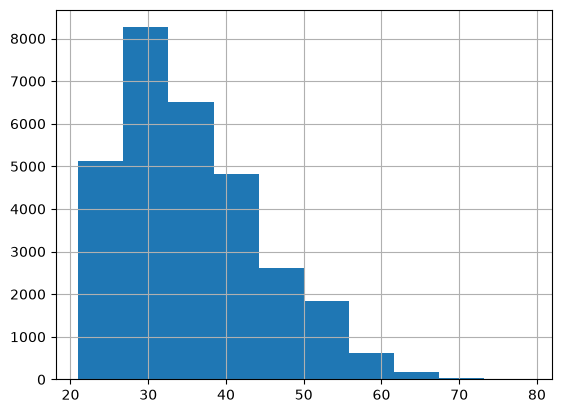

In [43]:
display(
    df["age"].value_counts().sort_index()
    .rename_axis("age").to_frame("count")
    
)

(df["age"].hist())


In [48]:
bill_amounts = [col for col in df.columns if col.startswith('bill')]

In [53]:
import numpy as np

In [55]:
df[bill_amounts].describe().round().rename(index={'50%': 'median'})

,bill_amt1,bill_amt2,bill_amt3,bill_amt4,bill_amt5,bill_amt6
count,30000.0,30000.0,30000.0,30000.0,30000.0,30000.0
mean,51223.0,49179.0,47013.0,43263.0,40311.0,38872.0
std,73636.0,71174.0,69349.0,64333.0,60797.0,59554.0
min,-165580.0,-69777.0,-157264.0,-170000.0,-81334.0,-339603.0
25%,3559.0,2985.0,2666.0,2327.0,1763.0,1256.0
median,22382.0,21200.0,20088.0,19052.0,18104.0,17071.0
75%,67091.0,64006.0,60165.0,54506.0,50190.0,49198.0
max,964511.0,983931.0,1664089.0,891586.0,927171.0,961664.0


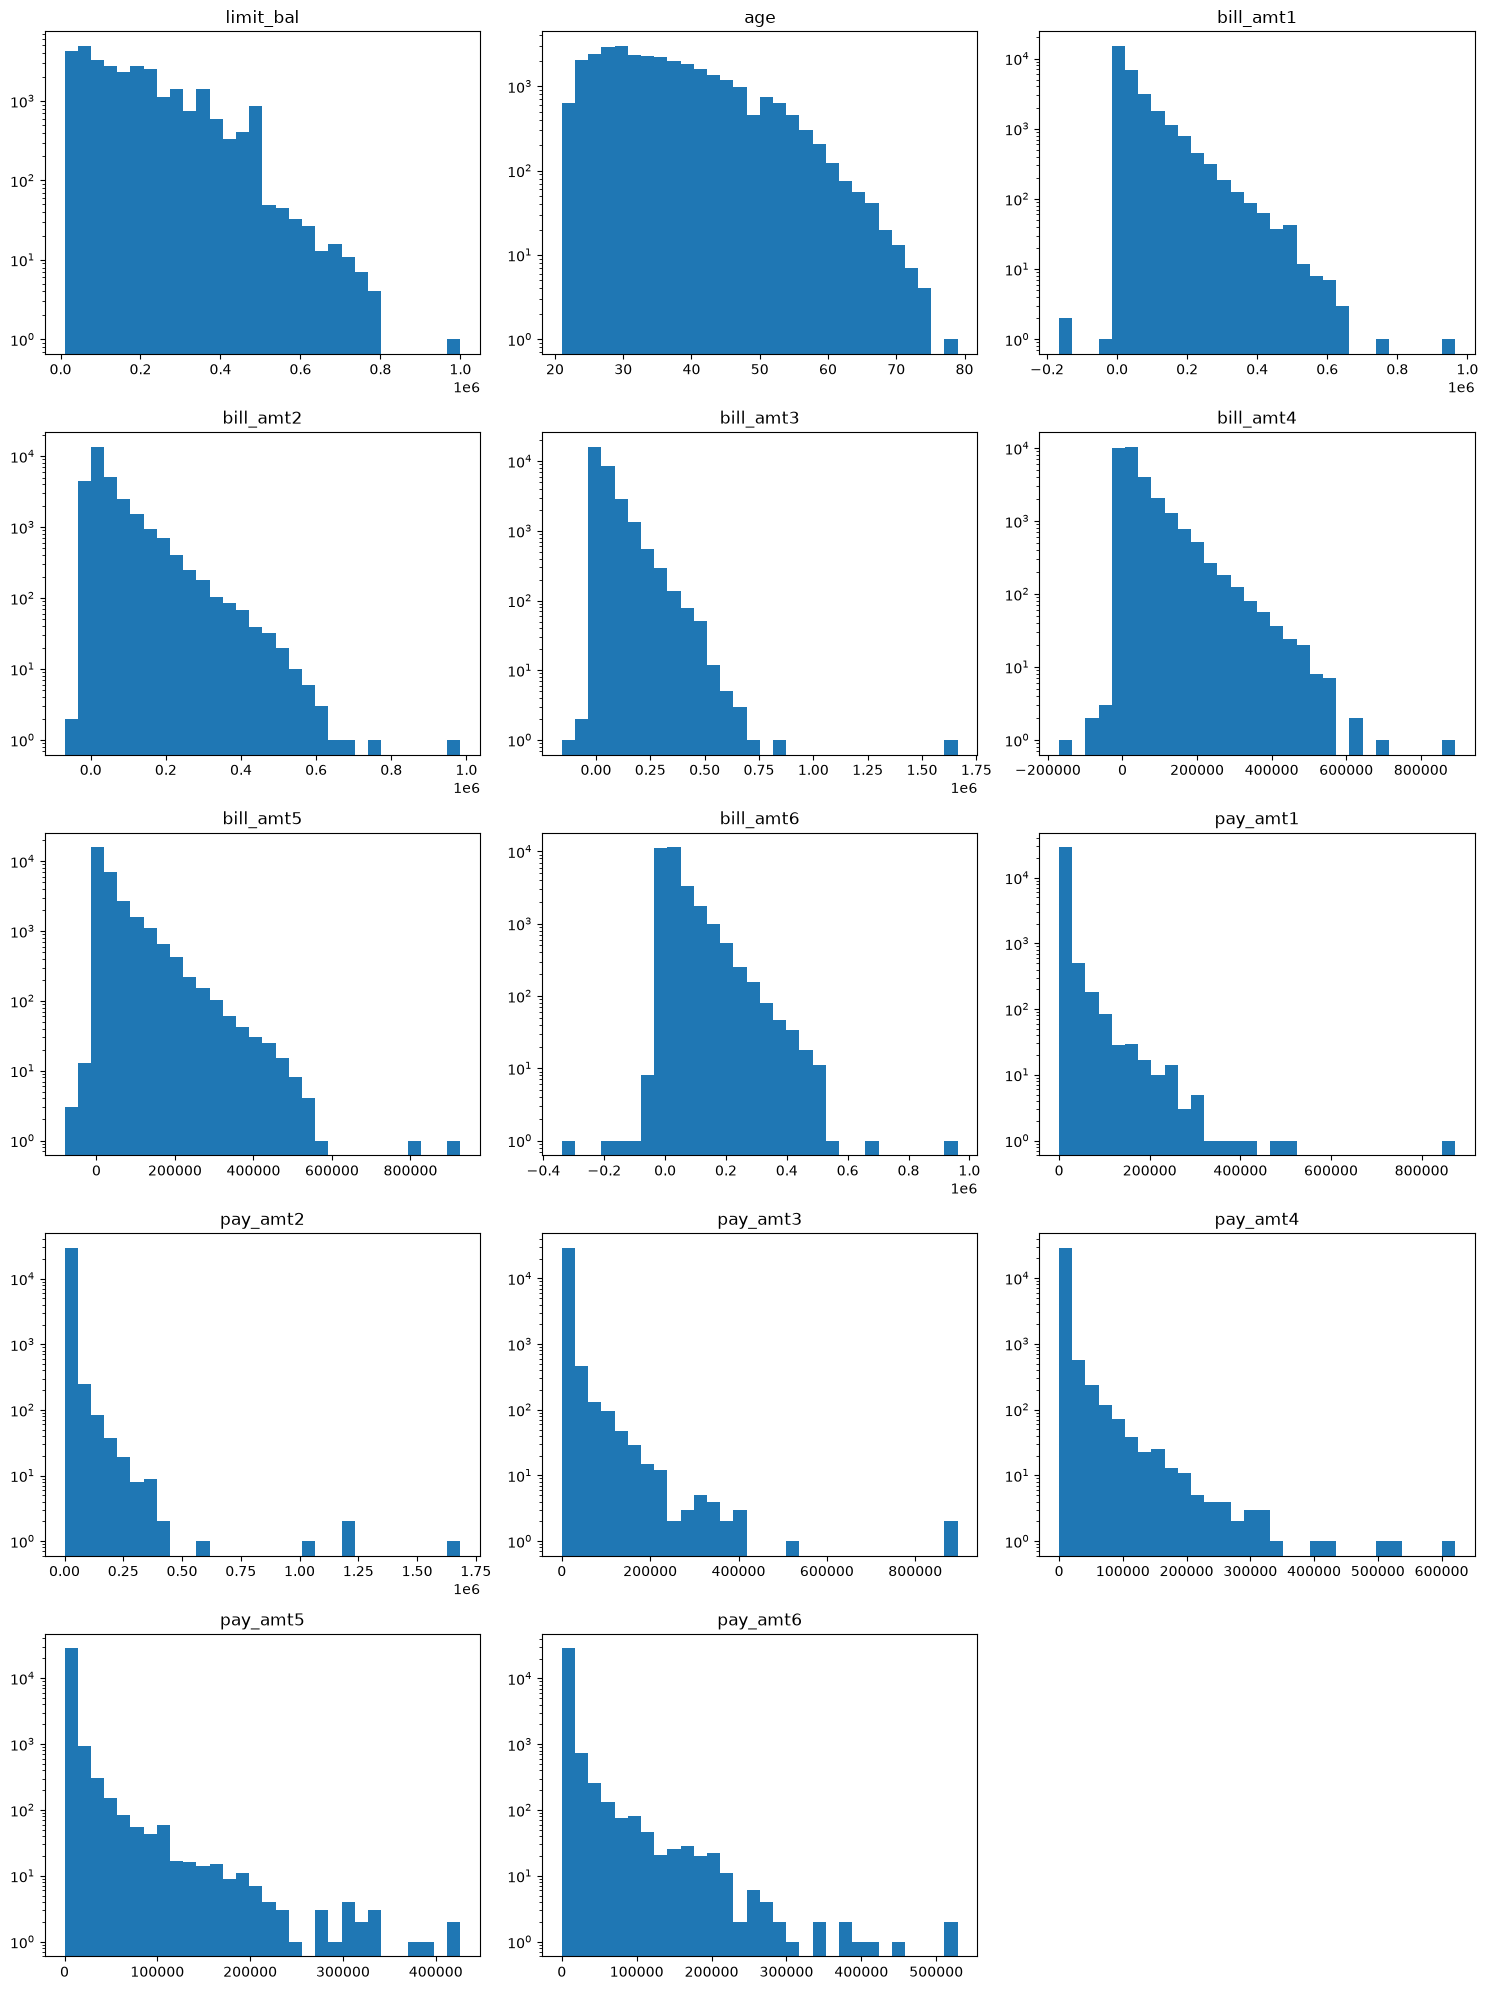

In [46]:
import math
import matplotlib.pyplot as plt

n = len(numeric_cols)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    ax.hist(df[col].dropna(), bins=30)
    ax.set_title(col)
    ax.set_yscale('log')

# nascondi assi vuoti
for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## Inspect repeated feature profiles

Group by all 23 predictors, excluding both ID and target. A repeated profile has at least two records. Concordant groups share one target value; discordant groups contain both outcomes. Counts of groups, participating records, and excess records describe different quantities. Identical observed profiles do not prove that records belong to the same person. Retain all records and use these findings when designing the split.

In [13]:
target = "default_payment_next_month"
feature_cols = df.columns.drop(["id", target]).tolist()
profile_groups = (
    df.groupby(feature_cols, dropna=False)[target]
    .agg(record_count="size", target_values="nunique", default_count="sum")
    .reset_index()
)
repeated_profiles = profile_groups.loc[profile_groups["record_count"].gt(1)].copy()
repeated_profiles["target_agreement"] = repeated_profiles["target_values"].map({
    1: "concordant", 2: "discordant",
})
profile_summary = (
    repeated_profiles.groupby("target_agreement")
    .agg(profile_groups=("record_count", "size"), records=("record_count", "sum"))
    .reindex(["concordant", "discordant"], fill_value=0)
)
profile_summary["excess_records"] = profile_summary["records"] - profile_summary["profile_groups"]
display(profile_summary)
display(repeated_profiles)
assert profile_groups["record_count"].sum() == len(df)


,profile_groups,records,excess_records
target_agreement,,,
concordant,31,62,31
discordant,21,46,25


,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,pay_5,...,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,record_count,target_values,default_count,target_agreement
1022,20000,1,2,2,24,2,2,4,4,4,...,0,0,0,0,0,0,3,2,2,discordant
5158,50000,1,2,2,26,1,-2,-2,-2,-2,...,0,0,0,0,0,0,2,1,0,concordant
6061,50000,2,1,2,23,1,-2,-2,-2,-2,...,0,0,0,0,0,0,2,1,0,concordant
6801,50000,2,2,2,22,1,-2,-2,-2,-2,...,0,0,0,0,0,0,2,2,1,discordant
9373,80000,1,1,2,37,1,-2,-2,-2,-2,...,0,0,0,0,0,0,2,2,1,discordant
9713,80000,1,3,2,27,1,-2,-2,-2,-2,...,0,0,0,0,0,0,2,2,1,discordant
10045,80000,2,2,1,31,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,2,1,0,concordant
10333,80000,2,2,2,25,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,2,1,0,concordant
10618,80000,2,3,1,42,-2,-2,-2,-2,-2,...,0,0,0,0,0,0,2,1,0,concordant
11076,90000,2,1,2,31,1,-2,-2,-2,-2,...,0,0,0,0,0,0,2,1,0,concordant


## Verify documented ranges and preserve the data

Compare the original data with the ranges in `../docs/data_documentation.md`. Confirm that this block has neither removed records nor changed values.

In [14]:
range_checks = pd.DataFrame({
    "observed_min": [df["limit_bal"].min(), df["age"].min(), df[bill_cols].min().min(), df[payment_cols].min().min()],
    "observed_max": [df["limit_bal"].max(), df["age"].max(), df[bill_cols].max().max(), df[payment_cols].max().max()],
    "documented_min": [10000, 21, -339603, 0],
    "documented_max": [1000000, 79, 1664089, 1684259],
}, index=["limit_bal", "age", "bill_amounts", "payment_amounts"])
display(range_checks)
assert range_checks["observed_min"].eq(range_checks["documented_min"]).all()
assert range_checks["observed_max"].eq(range_checks["documented_max"]).all()
assert df.shape == (30000, 25)
pd.testing.assert_frame_equal(df, data_before_descriptive_eda)
print("Documented ranges confirmed; all rows and values preserved.")


,observed_min,observed_max,documented_min,documented_max
limit_bal,10000,1000000,10000,1000000
age,21,79,21,79
bill_amounts,-339603,1664089,-339603,1664089
payment_amounts,0,1684259,0,1684259


Documented ranges confirmed; all rows and values preserved.


In [57]:
repeated_profiles["all_amounts_zero"] = (
    repeated_profiles[bill_cols + payment_cols]
    .eq(0)
    .all(axis=1)
)

pd.crosstab(
    repeated_profiles["target_agreement"],
    repeated_profiles["all_amounts_zero"],
    values=repeated_profiles["record_count"],
    aggfunc="sum"
).fillna(0)

all_amounts_zero,False,True
target_agreement,,
concordant,8,54
discordant,3,43


In [22]:
target_cols = ['default_payment_next_month']
feature_cols = [col for col in df.columns if col !='default_payment_next_month' ]

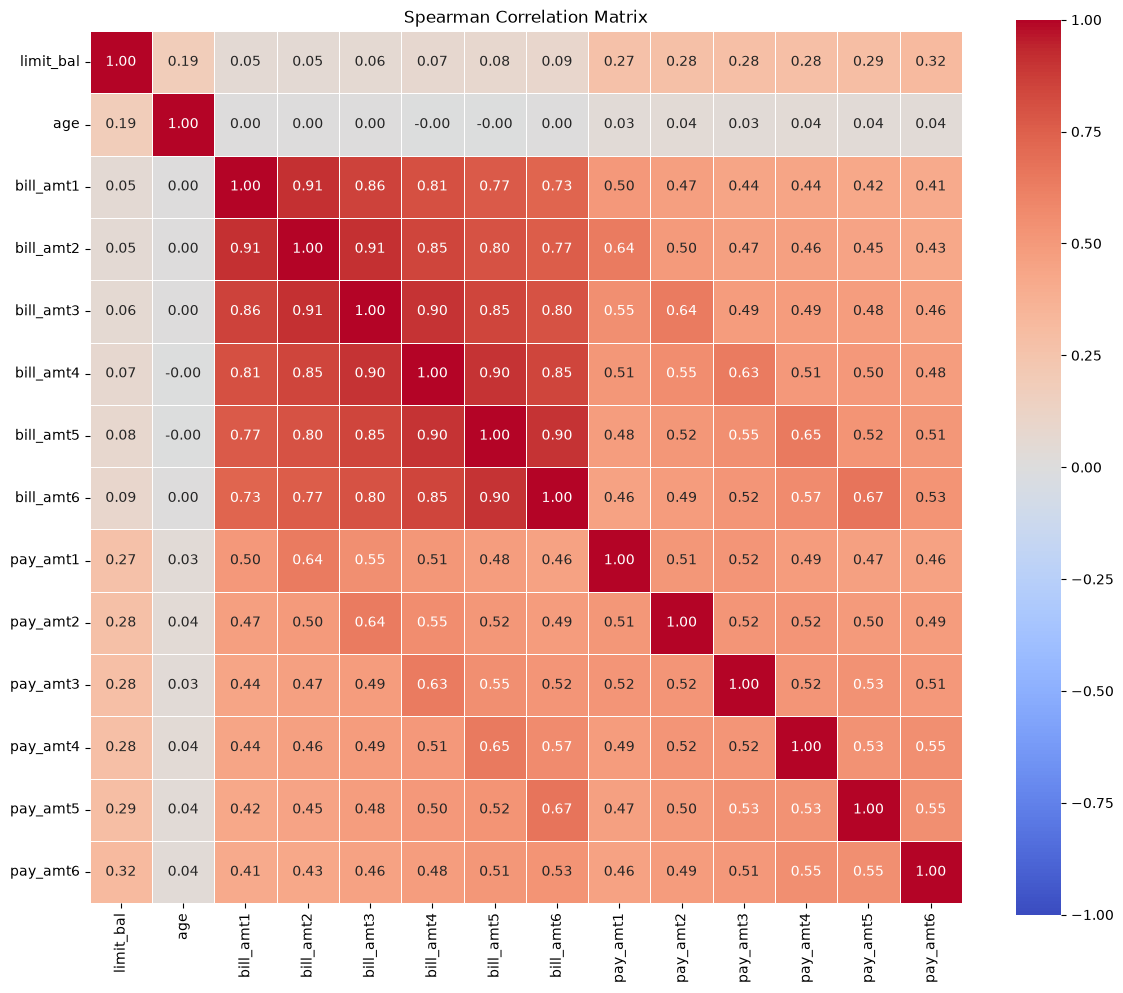

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

method = 'spearman'
# Pearson correlation: quantitative features
corr = df[numeric_cols].corr(method=method)

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
)

plt.title(f"{method.title()} Correlation Matrix")
plt.tight_layout()
plt.show()

In [63]:
for col in ['sex', 'education', 'marriage']:
    display(df[col].value_counts())


sex
2    18112
1    11888
Name: count, dtype: int64

education
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64

marriage
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64

In [64]:
pay_status_analysis = (
    df.groupby("pay_0")
    .agg(
        n=("pay_0", "size"),
        bill_zero_rate=("bill_amt1", lambda x: x.eq(0).mean()),
        bill_positive_rate=("bill_amt1", lambda x: x.gt(0).mean()),
        payment_zero_rate=("pay_amt1", lambda x: x.eq(0).mean()),
        median_bill=("bill_amt1", "median"),
        median_payment=("pay_amt1", "median"),
    )
)

display(pay_status_analysis)

,n,bill_zero_rate,bill_positive_rate,payment_zero_rate,median_bill,median_payment
pay_0,,,,,,
-2,2759,0.251540,0.672708,0.330555,1179.0,1131.0
-1,5686,0.000352,0.998945,0.179740,2739.5,1732.5
0,14737,0.000000,1.000000,0.017711,49605.0,3000.0
1,3688,0.355748,0.542028,0.593818,4606.5,0.0
2,2667,0.000000,1.000000,0.204349,41632.0,2000.0
3,322,0.000000,1.000000,0.618012,18354.0,0.0
4,76,0.000000,1.000000,0.763158,31633.0,0.0
5,26,0.000000,1.000000,0.884615,39752.5,0.0
6,11,0.000000,1.000000,1.000000,71310.0,0.0


In [65]:
education_unknown = df["education"].isin([0, 5, 6])
marriage_unknown = df["marriage"].eq(0)
repayment_unknown = df[repayment_cols].isin([-2, 0]).any(axis=1)

drop_mask = (
    education_unknown
    | marriage_unknown
    | repayment_unknown
)

print("Education unknown:", education_unknown.sum())
print("Marriage unknown:", marriage_unknown.sum())
print("Repayment unknown:", repayment_unknown.sum())

print("\nTotal records:", len(df))
print("Records removed:", drop_mask.sum())
print("Records remaining:", (~drop_mask).sum())
print("Percentage removed:", f"{drop_mask.mean():.2%}")

Education unknown: 345
Marriage unknown: 54
Repayment unknown: 25939

Total records: 30000
Records removed: 25970
Records remaining: 4030
Percentage removed: 86.57%


## Findings and open questions

### Verified observations

- The table contains 30,000 records, 23 predictors, an ID, and a binary target, with no pandas null values.
- Default prevalence is 22.12%; always predicting no default gives 77.88% accuracy on this full dataset.
- There are 35 excess identical records when excluding ID but retaining the target.
- Repeated predictor profiles include 31 concordant groups (62 records) and 21 discordant groups (46 records).
- Credit limits range from 10,000 to 1,000,000 NT$; ages range from 21 to 79.
- Statement balances range from -339,603 to 1,664,089 NT$; payments range from 0 to 1,684,259 NT$.
- Every repayment frequency column accounts for 30,000 observations. All original rows and values were preserved by this descriptive block.

### Open questions and next step

- Education codes 0, 5, and 6, marriage code 0, and repayment codes -2 and 0 lack definitions in the consulted UCI documentation. Preserve their values until a justified representation is chosen.
- Negative balances, extreme amounts, and repeated profiles need interpretation; no automatic deletion, recoding, or transformation has been applied.
- Define train/validation/test partitions and a policy for repeated profiles before exploring target relationships or fitting preprocessing. Consider stratification and explicitly check profile overlap across partitions.
- The dataset is historical; performance on other periods or populations has not been established.
- The deprecated `xlrd` reader remains a separate maintenance task.
